# Segmentasi Pelanggan Berdasarkan Pola Pembelian Menggunakan K-Means Clustering

**Dataset:** Online Retail (transaksi toko online UK, 01 Des 2010 – 09 Des 2011)
**Metode:** RFM (Recency, Frequency, Monetary) + K-Means Clustering

---
## 1. Latar Belakang dan Tujuan
Pada bisnis ritel online, pelanggan memiliki perilaku belanja yang sangat beragam. Memperlakukan semua pelanggan dengan strategi pemasaran yang sama kurang efisien. **Segmentasi pelanggan** mengelompokkan pelanggan yang berperilaku mirip sehingga strategi (promosi, retensi, reaktivasi) dapat disesuaikan per kelompok.

**Tujuan proyek:**
1. Membersihkan dan menyiapkan data transaksi menjadi data level pelanggan.
2. Membentuk fitur pola pembelian **RFM**.
3. Menentukan jumlah klaster optimal untuk K-Means (Elbow, Silhouette, Davies-Bouldin).
4. Menginterpretasi karakteristik tiap segmen dan memberi rekomendasi bisnis.

**Alur:** Data Understanding → Data Cleaning → Feature Engineering (RFM) → Preprocessing → Penentuan K → K-Means → Profiling & Interpretasi → Rekomendasi → Kesimpulan.

## 2. Import Library

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sns.set_style('whitegrid')
pd.options.display.float_format = '{:,.2f}'.format
RANDOM_STATE = 42

## 3. Data Understanding

In [2]:

import pandas as pd
import os

# Ganti dengan lokasi file CSV di komputer kamu
PATH = r"C:\Users\Asus\Downloads\projek data science klmpk\Online_Retail.csv"

# Periksa apakah file ditemukan
if not os.path.exists(PATH):
    print("File tidak ditemukan!")
    print("Silakan periksa kembali lokasi dan nama file CSV.")
else:
    # Membaca dataset
    df = pd.read_csv(PATH, encoding="latin-1")

    # Mengubah kolom InvoiceDate menjadi format tanggal
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

    # Menampilkan informasi dataset
    print("Ukuran data  :", df.shape)
    print(
        "Rentang waktu:",
        df["InvoiceDate"].min(),
        "s.d.",
        df["InvoiceDate"].max()
    )

    display(df.head())

Ukuran data  : (541909, 8)
Rentang waktu: 2010-12-01 08:26:00 s.d. 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [7]:
print("Missing Value Setiap Kolom:")
print(df.isna().sum())

print("Total Missing Value:")
print(df.isna().sum().sum())

Missing Value Setiap Kolom:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Total Missing Value:
136534


In [13]:
print("Jumlah Baris Duplikat:")
print(df.duplicated().sum())
print("Jumlah Baris Pembatalan:")
print(df["InvoiceNo"].astype(str).str.startswith("C").sum())
print("Jumlah Quantity <= 0:")
print((df["Quantity"] <= 0).sum())
print("Jumlah UnitPrice <= 0:")
print((df["UnitPrice"] <= 0).sum())
df.describe()

Jumlah Baris Duplikat:
5268
Jumlah Baris Pembatalan:
9288
Jumlah Quantity <= 0:
10624
Jumlah UnitPrice <= 0:
2517


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,"541,909.00",541909,"541,909.00","406,829.00"
mean,9.55,2011-07-04 13:34:57.156386048,4.61,"15,287.69"
min,"-80,995.00",2010-12-01 08:26:00,"-11,062.06","12,346.00"
25%,1.00,2011-03-28 11:34:00,1.25,"13,953.00"
50%,3.00,2011-07-19 17:17:00,2.08,"15,152.00"
75%,10.00,2011-10-19 11:27:00,4.13,"16,791.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,218.08,NaN,96.76,"1,713.60"


**Temuan awal:** terdapat ±135 ribu baris tanpa `CustomerID` (tidak bisa disegmentasi per pelanggan), baris duplikat, transaksi pembatalan, serta nilai `Quantity`/`UnitPrice` tidak valid (≤ 0). Semuanya perlu ditangani sebelum pemodelan.

## 4. Data Cleaning

In [9]:
n0 = len(df)
steps = []

d = df.dropna(subset=['CustomerID']);                         steps.append(('Hapus CustomerID kosong', len(d)))
d = d.drop_duplicates();                                      steps.append(('Hapus duplikat', len(d)))
d = d[~d['InvoiceNo'].astype(str).str.startswith('C')];       steps.append(('Hapus transaksi pembatalan (C)', len(d)))
d = d[(d['Quantity'] > 0) & (d['UnitPrice'] > 0)];            steps.append(('Hapus Quantity/UnitPrice <= 0', len(d)))
# Kode non-produk (ongkos kirim, biaya manual, dll.) bukan perilaku belanja produk
non_product = ['POST', 'M', 'DOT', 'PADS', 'D', 'C2', 'BANK CHARGES', 'AMAZONFEE', 'CRUK', 'S']
d = d[~d['StockCode'].astype(str).isin(non_product)];         steps.append(('Hapus kode non-produk (POST, M, DOT, dll.)', len(d)))

d = d.copy()
d['CustomerID'] = d['CustomerID'].astype(int)
d['TotalPrice'] = d['Quantity'] * d['UnitPrice']

log = pd.DataFrame(steps, columns=['Langkah', 'Sisa baris'])
log['Terhapus'] = log['Sisa baris'].shift(1, fill_value=n0) - log['Sisa baris']
display(log)
print(f'Data akhir: {len(d):,} baris | {d.CustomerID.nunique():,} pelanggan unik')

,Langkah,Sisa baris,Terhapus
0,Hapus CustomerID kosong,406829,135080
1,Hapus duplikat,401604,5225
2,Hapus transaksi pembatalan (C),392732,8872
3,Hapus Quantity/UnitPrice <= 0,392692,40
4,"Hapus kode non-produk (POST, M, DOT, dll.)",391150,1542


Data akhir: 391,150 baris | 4,334 pelanggan unik


## 5. Feature Engineering — RFM
Pola pembelian pelanggan diringkas dengan tiga fitur klasik **RFM**:

- **Recency (R):** berapa hari sejak pembelian terakhir (semakin kecil = semakin baru aktif).
- **Frequency (F):** jumlah transaksi (faktur) unik.
- **Monetary (M):** total nilai belanja (GBP).

Tanggal acuan (*snapshot date*) = 1 hari setelah transaksi terakhir pada dataset.

In [10]:
snapshot = d['InvoiceDate'].max() + pd.Timedelta(days=1)
g = d.groupby('CustomerID')

rfm = pd.DataFrame({
    'Recency'  : (snapshot - g['InvoiceDate'].max()).dt.days,
    'Frequency': g['InvoiceNo'].nunique(),
    'Monetary' : g['TotalPrice'].sum(),
})
# Fitur tambahan, hanya untuk profiling (tidak ikut klastering)
rfm['AvgBasket'] = rfm['Monetary'] / rfm['Frequency']
rfm['Products']  = g['StockCode'].nunique()
rfm['Quantity']  = g['Quantity'].sum()
rfm['Country']   = g['Country'].agg(lambda s: s.mode().iloc[0])

print('Snapshot date:', snapshot.date(), '| Jumlah pelanggan:', len(rfm))
rfm[['Recency','Frequency','Monetary']].describe()

Snapshot date: 2011-12-10 | Jumlah pelanggan: 4334


,Recency,Frequency,Monetary
count,"4,334.00","4,334.00","4,334.00"
mean,92.70,4.25,"2,015.97"
std,100.18,7.63,"8,903.67"
min,1.00,1.00,3.75
25%,18.00,1.00,304.24
50%,51.00,2.00,662.57
75%,143.00,5.00,"1,631.62"
max,374.00,206.00,"279,138.02"


## 6. Exploratory Data Analysis

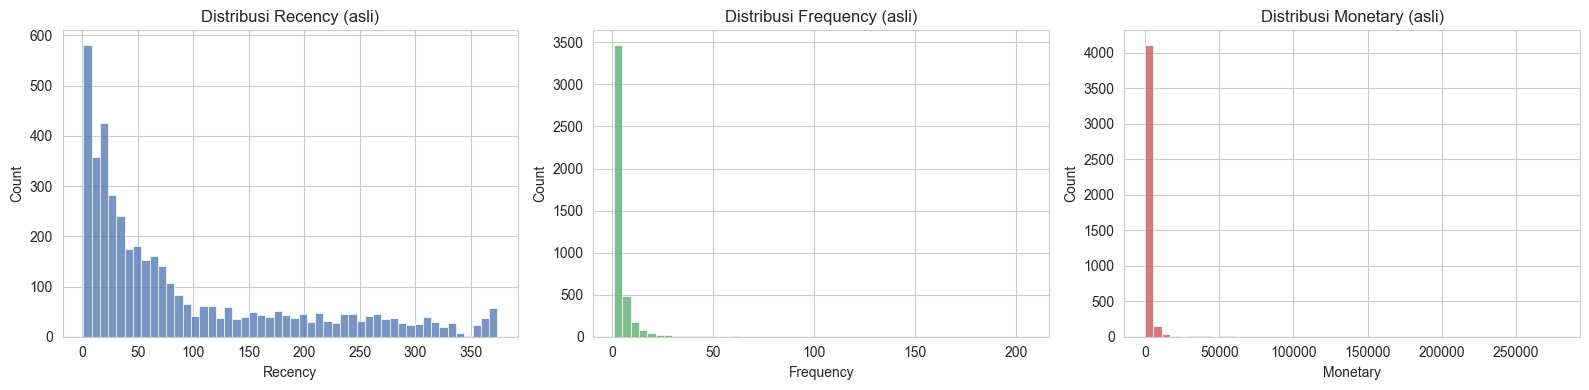

Skewness:
Recency      1.24
Frequency   11.95
Monetary    19.58
dtype: float64


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, c, col in zip(ax, ['Recency','Frequency','Monetary'], ['#4C72B0','#55A868','#C44E52']):
    sns.histplot(rfm[c], bins=50, color=col, ax=a); a.set_title(f'Distribusi {c} (asli)')
plt.tight_layout(); plt.show()
print('Skewness:'); print(rfm[['Recency','Frequency','Monetary']].skew().round(2))

**Interpretasi:** ketiga fitur, terutama *Frequency* dan *Monetary*, sangat **miring ke kanan (right-skewed)** — sebagian kecil pelanggan bernilai sangat besar. K-Means berbasis jarak Euclidean sensitif terhadap skala dan skewness, sehingga diperlukan **transformasi log** dan **standardisasi**.

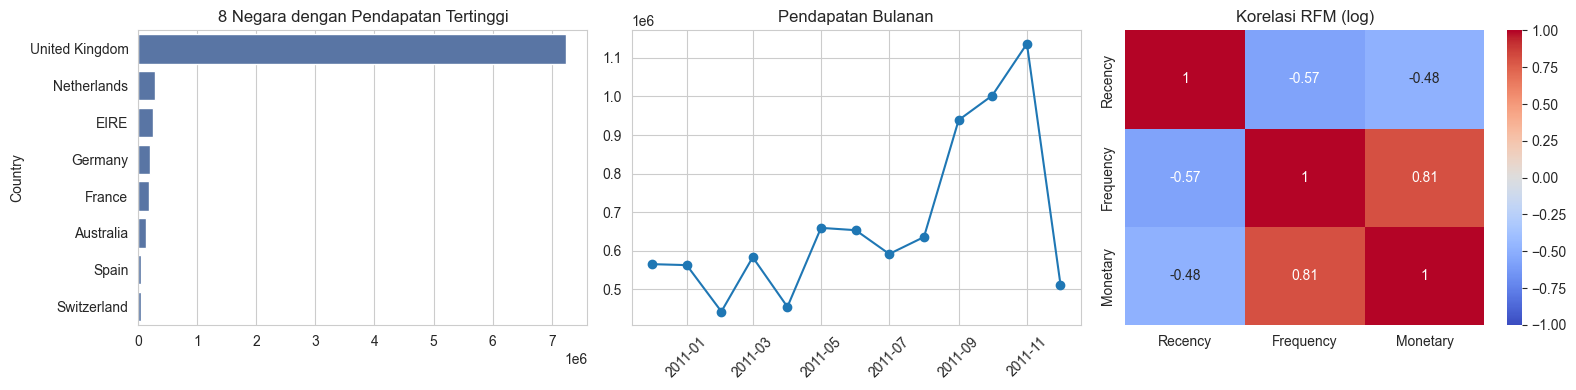

Kontribusi pendapatan United Kingdom: 82.9%


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
top = d.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False).head(8)
sns.barplot(x=top.values, y=top.index, color='#4C72B0', ax=ax[0]); ax[0].set_title('8 Negara dengan Pendapatan Tertinggi')
monthly = d.set_index('InvoiceDate')['TotalPrice'].resample('MS').sum()
ax[1].plot(monthly.index, monthly.values, marker='o'); ax[1].set_title('Pendapatan Bulanan'); ax[1].tick_params(axis='x', rotation=45)
sns.heatmap(np.log1p(rfm[['Recency','Frequency','Monetary']]).corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title('Korelasi RFM (log)')
plt.tight_layout(); plt.show()
print(f"Kontribusi pendapatan United Kingdom: {d.loc[d.Country=='United Kingdom','TotalPrice'].sum()/d.TotalPrice.sum():.1%}")

## 7. Preprocessing
1. **Transformasi `log1p`** untuk meredam skewness.
2. **StandardScaler** agar ketiga fitur berskala sama (mean 0, std 1).

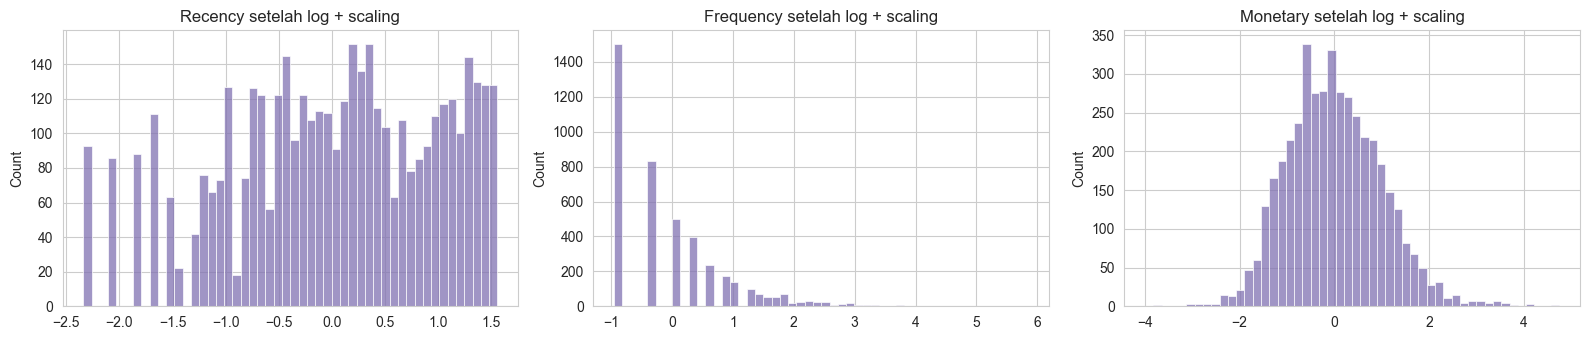

In [13]:
features = ['Recency', 'Frequency', 'Monetary']
X_log = np.log1p(rfm[features])
scaler = StandardScaler()
X = scaler.fit_transform(X_log)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
for i, c in enumerate(features):
    sns.histplot(X[:, i], bins=50, color='#8172B2', ax=ax[i]); ax[i].set_title(f'{c} setelah log + scaling')
plt.tight_layout(); plt.show()

## 8. Penentuan Jumlah Klaster (K) Optimal
Digunakan empat metrik pada K = 2 … 10:
- **Elbow (Inertia/WCSS)** — cari titik tekuk, semakin kecil semakin kompak.
- **Silhouette Score** — semakin besar semakin baik (maks. 1).
- **Davies-Bouldin Index** — semakin kecil semakin baik.
- **Calinski-Harabasz** — semakin besar semakin baik.

,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz
K,,,,
2,"6,476.63",0.43,0.89,"4,364.61"
3,"4,861.42",0.34,1.05,"3,626.28"
4,"3,931.76",0.34,1.01,"3,329.68"
5,"3,290.12",0.32,0.99,"3,194.66"
6,"2,849.83",0.31,1.01,"3,083.61"
7,"2,546.93",0.31,0.97,"2,960.37"
8,"2,334.25",0.30,0.99,"2,824.33"
9,"2,156.73",0.28,1.02,"2,718.59"
10,"1,999.58",0.28,1.02,"2,643.59"


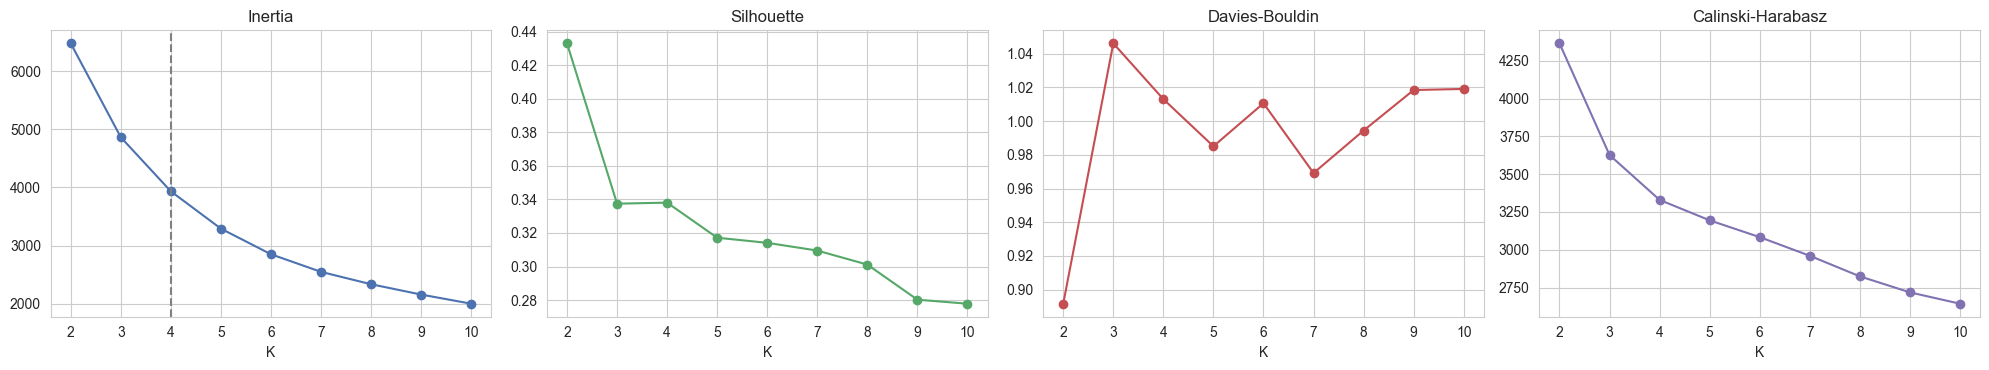

In [14]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    rows.append([k, km.inertia_, silhouette_score(X, km.labels_),
                 davies_bouldin_score(X, km.labels_), calinski_harabasz_score(X, km.labels_)])
ev = pd.DataFrame(rows, columns=['K','Inertia','Silhouette','Davies-Bouldin','Calinski-Harabasz']).set_index('K')
display(ev)

fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
for a, c, col in zip(ax, ev.columns, ['#4C72B0','#55A868','#C44E52','#8172B2']):
    a.plot(ev.index, ev[c], marker='o', color=col); a.set_title(c); a.set_xlabel('K')
ax[0].axvline(4, ls='--', c='gray'); plt.tight_layout(); plt.show()

**Analisis pemilihan K:**
- Silhouette tertinggi memang pada **K = 2** (±0,43), tetapi pembagian dua kelompok terlalu kasar (hanya "aktif" vs "tidak aktif") dan kurang berguna untuk strategi pemasaran.
- Kurva **Elbow** mulai melandai sekitar **K = 4**; pada K = 4 Silhouette (±0,34) setara dengan K = 3 dan Davies-Bouldin sedikit lebih baik (±1,01 vs ±1,05). Calinski-Harabasz memang lebih tinggi pada K = 3, namun selisihnya kecil dibanding manfaat pemisahan segmen yang lebih rinci.
- Dengan mempertimbangkan **kualitas statistik sekaligus kegunaan bisnis**, dipilih **K = 4**.

## 9. Pemodelan K-Means (K = 4)

In [15]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
rfm['Cluster'] = kmeans.labels_

print(f'Silhouette Score    : {silhouette_score(X, kmeans.labels_):.4f}')
print(f'Davies-Bouldin Index: {davies_bouldin_score(X, kmeans.labels_):.4f}')
print(f'Calinski-Harabasz   : {calinski_harabasz_score(X, kmeans.labels_):.2f}')
rfm['Cluster'].value_counts().sort_index()

Silhouette Score    : 0.3381
Davies-Bouldin Index: 1.0131
Calinski-Harabasz   : 3329.68


Cluster
0     686
1    1636
2    1177
3     835
Name: count, dtype: int64

## 10. Profiling dan Interpretasi Segmen

In [16]:
profile = rfm.groupby('Cluster').agg(
    Jumlah=('Recency', 'size'),
    Recency=('Recency', 'mean'), Frequency=('Frequency', 'mean'), Monetary=('Monetary', 'mean'),
    Median_Recency=('Recency', 'median'), Median_Frequency=('Frequency', 'median'), Median_Monetary=('Monetary', 'median'),
    AvgBasket=('AvgBasket', 'mean'), Products=('Products', 'mean'),
)
profile['Persen_Pelanggan'] = profile['Jumlah'] / profile['Jumlah'].sum() * 100
profile['Total_Pendapatan'] = rfm.groupby('Cluster')['Monetary'].sum()
profile['Persen_Pendapatan'] = profile['Total_Pendapatan'] / profile['Total_Pendapatan'].sum() * 100

# Penamaan segmen otomatis berdasarkan karakteristik pusat klaster
m = profile
champ   = m['Monetary'].idxmax()
lost    = m['Recency'].idxmax()
rest    = [c for c in m.index if c not in (champ, lost)]
newc    = m.loc[rest, 'Monetary'].idxmin()          # recency rendah, nilai belanja kecil
regular = [c for c in rest if c != newc][0]
names = {champ: 'Champions (Loyal Bernilai Tinggi)', lost: 'Lost / Hibernating (Tidak Aktif)',
         newc: 'Pelanggan Baru / Berpotensi', regular: 'Pelanggan Reguler (Perlu Perhatian)'}
rfm['Segment'] = rfm['Cluster'].map(names)
profile['Segment'] = profile.index.map(names)
profile.set_index('Segment').round(1)

,Jumlah,Recency,Frequency,Monetary,Median_Recency,Median_Frequency,Median_Monetary,AvgBasket,Products,Persen_Pelanggan,Total_Pendapatan,Persen_Pendapatan
Segment,,,,,,,,,,,,
Champions (Loyal Bernilai Tinggi),686,11.80,13.90,"8,168.70",8.00,10.00,"3,728.80",625.30,156.90,15.80,"5,603,729.80",64.10
Lost / Hibernating (Tidak Aktif),1636,182.70,1.30,350.10,176.50,1.00,298.40,287.20,22.30,37.70,"572,713.80",6.60
Pelanggan Reguler (Perlu Perhatian),1177,67.50,4.20,"1,797.60",52.00,4.00,"1,356.30",570.70,74.30,27.20,"2,115,806.40",24.20
Pelanggan Baru / Berpotensi,835,18.30,2.10,532.90,17.00,2.00,460.60,275.80,41.50,19.30,"444,977.50",5.10


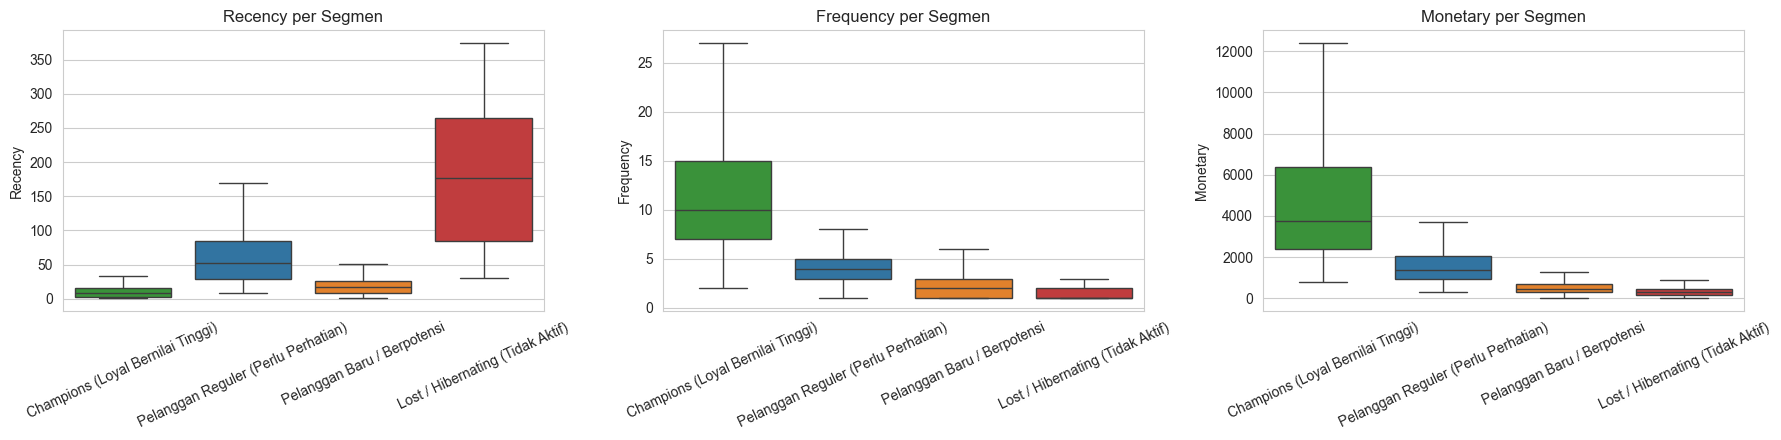

In [17]:
order = ['Champions (Loyal Bernilai Tinggi)', 'Pelanggan Reguler (Perlu Perhatian)',
         'Pelanggan Baru / Berpotensi', 'Lost / Hibernating (Tidak Aktif)']
palette = dict(zip(order, ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728']))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, c in zip(ax, features):
    sns.boxplot(data=rfm, x='Segment', y=c, order=order, palette=palette, showfliers=False, ax=a)
    a.set_title(f'{c} per Segmen'); a.set_xlabel(''); a.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

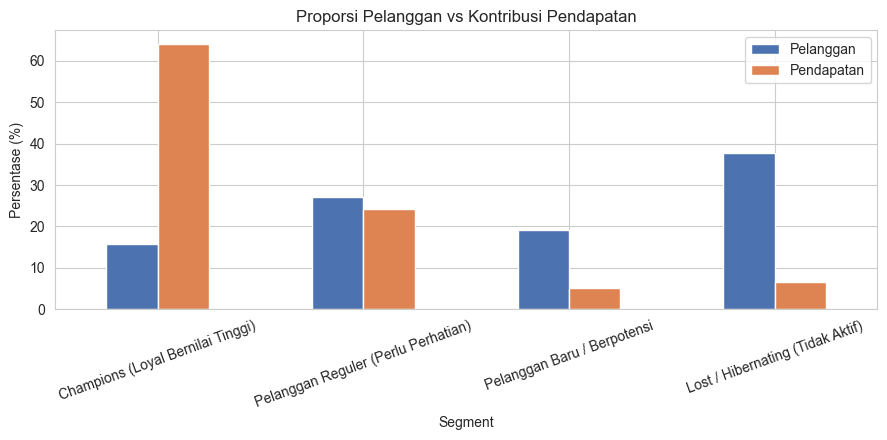

,Pelanggan,Pendapatan
Segment,,
Champions (Loyal Bernilai Tinggi),15.80,64.10
Pelanggan Reguler (Perlu Perhatian),27.20,24.20
Pelanggan Baru / Berpotensi,19.30,5.10
Lost / Hibernating (Tidak Aktif),37.70,6.60


In [18]:
# Proporsi pelanggan vs kontribusi pendapatan
sg = rfm.groupby('Segment').agg(Pelanggan=('Monetary','size'), Pendapatan=('Monetary','sum')).loc[order]
sg = sg / sg.sum() * 100
sg.plot(kind='bar', figsize=(9, 4.5), color=['#4C72B0', '#DD8452'])
plt.ylabel('Persentase (%)'); plt.title('Proporsi Pelanggan vs Kontribusi Pendapatan'); plt.xticks(rotation=20)
plt.tight_layout(); plt.show()
sg.round(1)

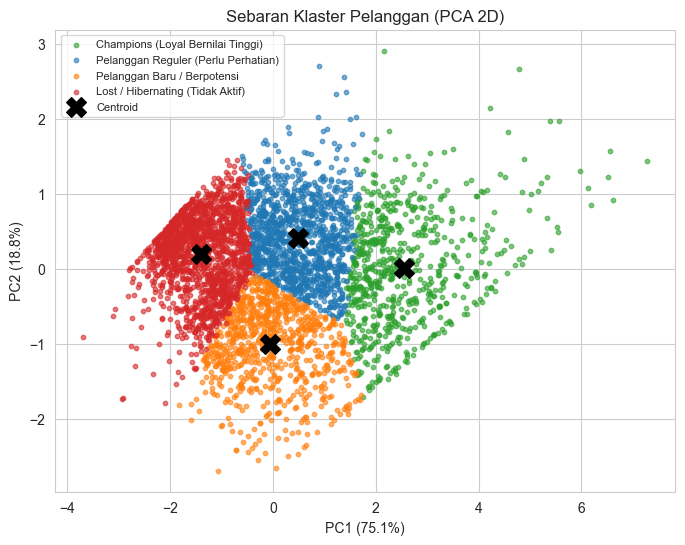

Total varians dijelaskan 2 komponen: 93.9%


In [19]:
# Visualisasi klaster dengan PCA 2D
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X)
plt.figure(figsize=(8, 6))
for s in order:
    idx = (rfm['Segment'] == s).values
    plt.scatter(Z[idx, 0], Z[idx, 1], s=10, alpha=.6, label=s, color=palette[s])
cen = pca.transform(kmeans.cluster_centers_)
plt.scatter(cen[:, 0], cen[:, 1], c='black', marker='X', s=200, label='Centroid')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})'); plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
plt.title('Sebaran Klaster Pelanggan (PCA 2D)'); plt.legend(fontsize=8); plt.show()
print(f'Total varians dijelaskan 2 komponen: {pca.explained_variance_ratio_.sum():.1%}')

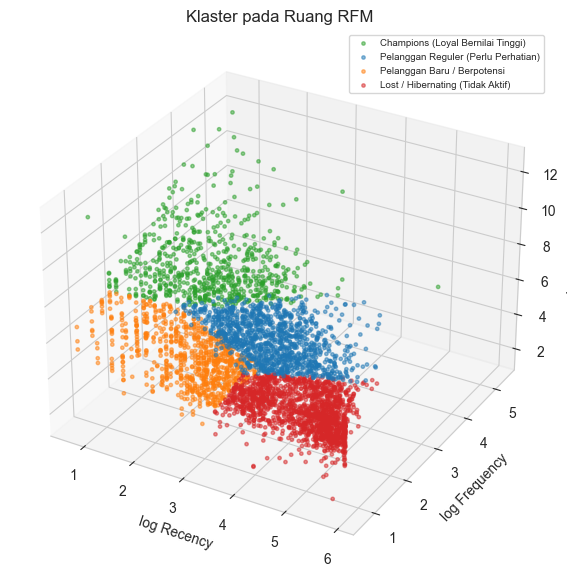

In [20]:
# Visualisasi 3D pada ruang RFM (log)
fig = plt.figure(figsize=(8, 7)); ax = fig.add_subplot(111, projection='3d')
for s in order:
    sub = X_log[(rfm['Segment'] == s).values]
    ax.scatter(sub['Recency'], sub['Frequency'], sub['Monetary'], s=6, alpha=.5, label=s, color=palette[s])
ax.set_xlabel('log Recency'); ax.set_ylabel('log Frequency'); ax.set_zlabel('log Monetary')
ax.legend(fontsize=7); plt.title('Klaster pada Ruang RFM'); plt.show()

In [21]:
# Profil negara tiap segmen (5 negara teratas)
pd.crosstab(rfm['Country'], rfm['Segment']).assign(Total=lambda t: t.sum(axis=1)).sort_values('Total', ascending=False).head(5)

Segment,Champions (Loyal Bernilai Tinggi),Lost / Hibernating (Tidak Aktif),Pelanggan Baru / Berpotensi,Pelanggan Reguler (Perlu Perhatian),Total
Country,,,,,
United Kingdom,612,1491,763,1050,3916
Germany,23,26,21,24,94
France,19,30,15,23,87
Spain,3,8,8,10,29
Belgium,5,6,2,11,24


### Interpretasi Segmen
| Segmen | Karakteristik | Makna Bisnis |
|---|---|---|
| **Champions (Loyal Bernilai Tinggi)** | Recency sangat rendah (baru belanja), Frequency tinggi (±14 transaksi), Monetary tertinggi | Pelanggan terbaik; porsi pelanggan kecil namun menyumbang pendapatan paling besar |
| **Pelanggan Reguler (Perlu Perhatian)** | Recency menengah (±2 bulan), Frequency ±4, Monetary menengah | Pelanggan cukup bernilai yang mulai menjauh; berisiko pindah bila tidak dijaga |
| **Pelanggan Baru / Berpotensi** | Recency rendah, Frequency ±2, Monetary kecil | Pelanggan aktif baru; potensi tumbuh menjadi loyal |
| **Lost / Hibernating (Tidak Aktif)** | Recency tertinggi (±6 bulan lebih), Frequency ±1, Monetary terendah | Pelanggan yang sudah lama tidak kembali; paling banyak jumlahnya tetapi kontribusi pendapatan kecil |

**Temuan kunci (dari tabel profil):**
- **Champions** hanya **±15,8%** pelanggan tetapi menyumbang **±64,1%** pendapatan (rata-rata ±14 transaksi, belanja terakhir ±12 hari lalu, ±157 produk berbeda).
- **Pelanggan Reguler** (±27,2% pelanggan) menyumbang ±24,2% pendapatan; recency ±68 hari, sehingga perlu dijaga agar tidak turun menjadi tidak aktif.
- **Lost/Hibernating** adalah kelompok terbesar (±37,7%) tetapi hanya ±6,6% pendapatan; rata-rata tidak berbelanja ±183 hari dan hampir semuanya hanya 1 kali transaksi.
- **Pelanggan Baru/Berpotensi** (±19,3%) aktif baru (recency ±18 hari) dengan ±2 transaksi dan nilai belanja masih kecil (±5,1% pendapatan).
- Seluruh segmen didominasi pelanggan United Kingdom, sejalan dengan dominasi pasar (±83% pendapatan).

## 11. Rekomendasi Strategi Bisnis

In [22]:
reco = pd.DataFrame({
 'Segment': order,
 'Strategi': [
  'Program loyalitas/VIP, akses awal produk baru, reward poin, layanan prioritas; jaga agar tidak churn',
  'Email personal & rekomendasi produk, voucher terbatas waktu, pengingat belanja ulang, bundling hemat',
  'Onboarding & sambutan, diskon pembelian kedua, cross-selling produk populer, dorong repeat order',
  'Kampanye win-back (diskon besar/gratis ongkir), survei alasan berhenti, batasi biaya pemasaran bila tidak merespons'],
}).set_index('Segment')
pd.set_option('display.max_colwidth', None); reco

,Strategi
Segment,
Champions (Loyal Bernilai Tinggi),"Program loyalitas/VIP, akses awal produk baru, reward poin, layanan prioritas; jaga agar tidak churn"
Pelanggan Reguler (Perlu Perhatian),"Email personal & rekomendasi produk, voucher terbatas waktu, pengingat belanja ulang, bundling hemat"
Pelanggan Baru / Berpotensi,"Onboarding & sambutan, diskon pembelian kedua, cross-selling produk populer, dorong repeat order"
Lost / Hibernating (Tidak Aktif),"Kampanye win-back (diskon besar/gratis ongkir), survei alasan berhenti, batasi biaya pemasaran bila tidak merespons"


## 12. Keterbatasan dan Saran Pengembangan
- Dataset hanya mencakup ±1 tahun dan didominasi pelanggan United Kingdom, sehingga hasil belum tentu berlaku untuk pasar lain.
- Hanya pelanggan ber-`CustomerID` yang tersegmentasi (±25% baris transaksi dibuang karena tidak memiliki ID).
- Nilai Silhouette ±0,34 menunjukkan klaster **cukup terpisah namun tidak sangat tegas** — wajar karena perilaku pelanggan bersifat kontinu.
- Pengembangan: bandingkan dengan **K-Medoids / Gaussian Mixture / DBSCAN**, tambahkan fitur (keragaman produk, interval antar-pembelian), dan lakukan analisis kohort/CLV.

## 13. Kesimpulan
1. Dari 541.909 baris transaksi, setelah pembersihan diperoleh **4.334 pelanggan unik** yang dirangkum menjadi fitur **RFM**.
2. Dengan transformasi log + standardisasi dan evaluasi Elbow, Silhouette, Davies-Bouldin, serta Calinski-Harabasz, jumlah klaster **K = 4** dipilih sebagai kompromi antara kualitas statistik dan kegunaan bisnis.
3. Terbentuk empat segmen: **Champions, Pelanggan Reguler, Pelanggan Baru/Berpotensi, dan Lost/Hibernating**, masing-masing dengan strategi pemasaran berbeda.
4. Segmen **Champions** (±16% pelanggan) menyumbang ±64% pendapatan (prinsip Pareto), sehingga retensinya menjadi prioritas utama.

In [23]:
# Simpan hasil segmentasi
out = rfm.reset_index()[['CustomerID','Recency','Frequency','Monetary','AvgBasket','Products','Country','Cluster','Segment']]
out.to_csv('hasil_segmentasi_pelanggan.csv', index=False)
out.head()

,CustomerID,Recency,Frequency,Monetary,AvgBasket,Products,Country,Cluster,Segment
0,12346,326,1,"77,183.60","77,183.60",1,United Kingdom,2,Pelanggan Reguler (Perlu Perhatian)
1,12347,2,7,"4,310.00",615.71,103,Iceland,0,Champions (Loyal Bernilai Tinggi)
2,12348,75,4,"1,437.24",359.31,21,Finland,2,Pelanggan Reguler (Perlu Perhatian)
3,12349,19,1,"1,457.55","1,457.55",72,Italy,3,Pelanggan Baru / Berpotensi
4,12350,310,1,294.40,294.40,16,Norway,1,Lost / Hibernating (Tidak Aktif)
